<a href="https://colab.research.google.com/github/clock-s/Homeworks/blob/main/ICA_Homework_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Neste Homework, tentaremos criar um método/modelo para descobrir a qualidade do vinho, independente de ele ser branco ou tinto

# Preparações iniciais

## Bibliotecas Utilizadas

In [262]:
import numpy as np
from numpy.linalg import eig
from numpy.linalg import inv
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import math
from sklearn.neural_network import MLPClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge



!git clone https://github.com/clock-s/Homeworks

fatal: destination path 'Homeworks' already exists and is not an empty directory.


## Pegando o dataset

In [263]:
# fetch dataset
white_wine = pd.read_csv('/content/Homeworks/winequality-white.csv', sep=';')
#white_wine = white_wine.drop(columns=['quality'])


red_wine = pd.read_csv('/content/Homeworks/winequality-red.csv', sep=';')
#red_wine = red_wine.drop(columns=['quality'])

wine_quality = pd.concat([white_wine, red_wine], ignore_index=True)

n_vinho_branco = white_wine[white_wine.columns[0]].count()
n_vinho_vermelho = red_wine[red_wine.columns[0]].count()
tamanho = wine_quality[wine_quality.columns[0]].count()

preditores = wine_quality.columns.size

total = wine_quality.to_numpy().transpose()
red = red_wine.to_numpy().transpose()
white = white_wine.to_numpy().transpose()

In [264]:
media_total = []
desvio_padrao_total = []


media_red = []
desvio_padrao_red = []

media_white = []
desvio_padrao_white = []



for i in range(0, preditores):
  media_total.append(total[i].mean())
  desvio_padrao_total.append(total[i].std())


  media_red.append(red[i].mean())
  desvio_padrao_red.append(red[i].std())

  media_white.append(white[i].mean())
  desvio_padrao_white.append(white[i].std())

## Funções que poderão ser uteis

In [265]:
def skewness(array):
  media = array.mean()
  dp = array.std()
  n = array.size

  n_part = n / ((n-1)*(n-2))

  samples_part = np.sum(((array - media)/dp)**3)

  skew = n_part * samples_part

  return skew


def cov(a:np.array, b:np.array):
  a_mean = a.mean()
  b_mean = b.mean()
  n = a.size

  sum = 0
  for i in range(0, n):
    sum += (a[i] - a_mean)*(b[i] - b_mean)

  covariance = sum/(n-1)

  return covariance




# QUESTÃO 0

Para esta questão, já como no homework anterior, já fizemos a análise mais aprofundada dos dados, para está etapa, iremos somente tratas os dados, em que o problema principal do dataset é a distribuição dele, seu skewness, em que há preditores cuja distribuição é bastante desigual/não equilibrada.

Dessa forma, o método encontrado para diminuir o skewness sem grandes esforços e sem se precoupar com vazamento de dados (usar parametro de tratamento considerando o teste), foi testado algumas alternativas, com a raiz quadrada e o log(1+x), pois eles independem dos dados. Por fim, pela natureza dos parametros, o tratamento foi a utlização do log(x), pois a natureza dos dados permitiu, fazendo com que o skewness fosse alterado como se pode ver nas analises abaixo.


## Tramaneto dos dados

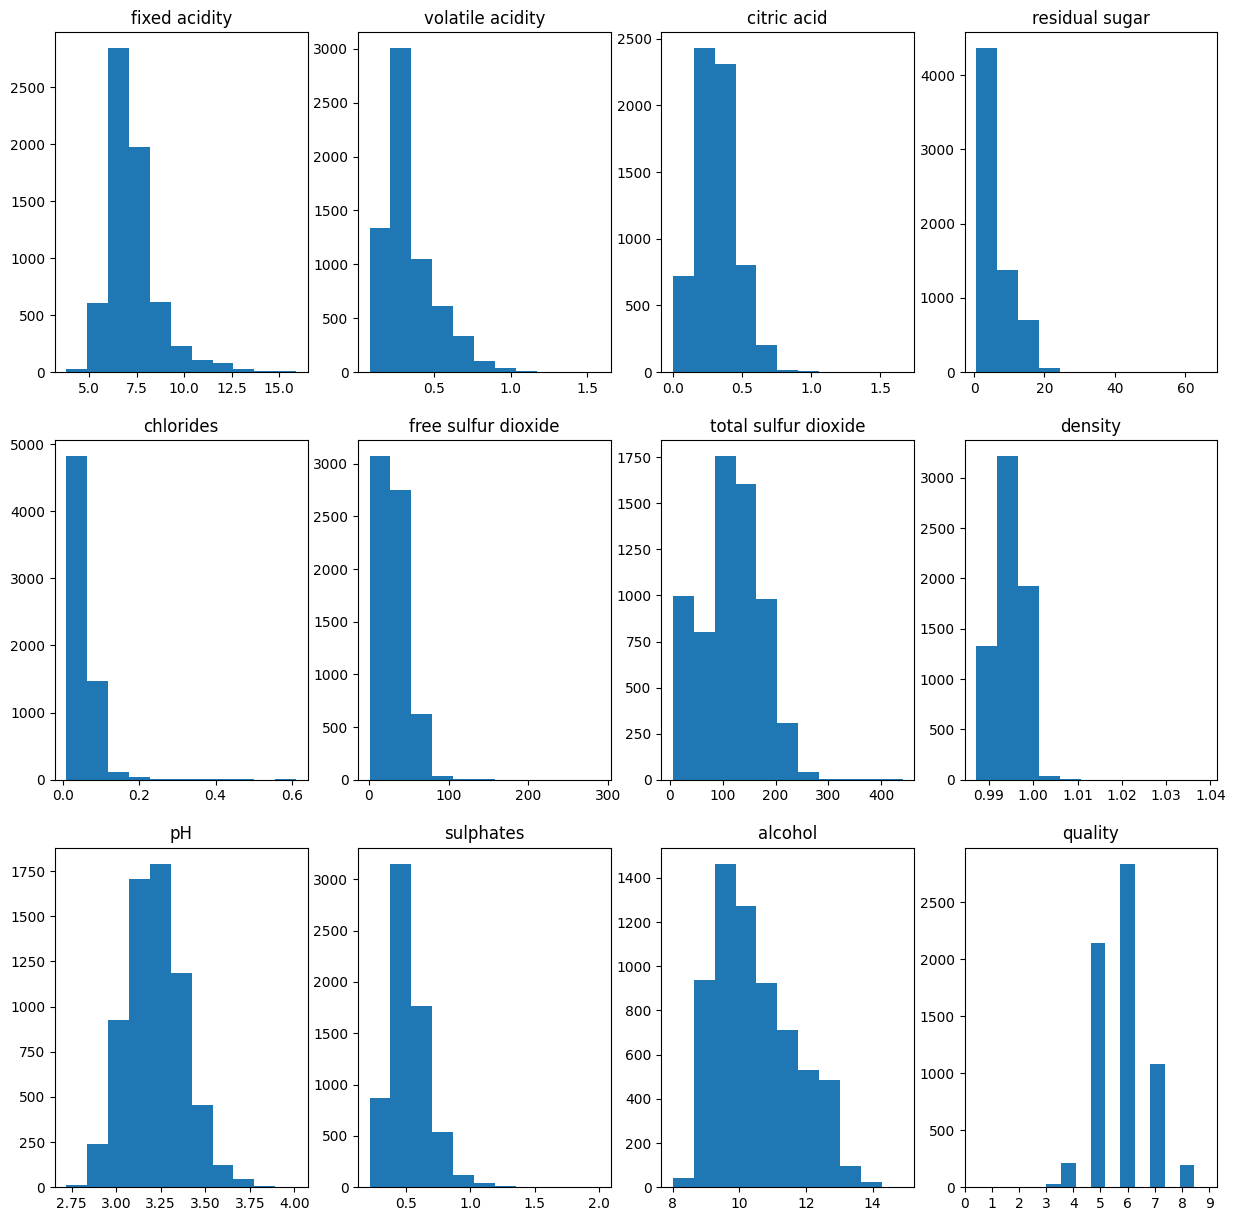

In [266]:
lines = 3
com = 4

fig, ax = plt.subplots(lines, com)
fig.set_figwidth(15)
fig.set_figheight(15)

for i in range(0, lines):
  for j in range(0, com):
    ax[i][j].hist(total[i*com + j], bins=11)
    ax[i][j].set_title(wine_quality.columns[i*com + j])

ax[lines-1][com-1].set_xticks(range(0, 10))

plt.show()

In [267]:
skew = []
for i in range(0, preditores):
  skew.append(skewness(total[i]))

print("Skewness:")
for i in range(0, preditores):
  print(f'\t{wine_quality.columns[i]}: {skew[i]}')

Skewness:
	fixed acidity: 1.7236875891852408
	volatile acidity: 1.4954417903857984
	citric acid: 0.47183960463768954
	residual sugar: 1.4357357266521111
	chlorides: 5.401074661358807
	free sulfur dioxide: 1.2203478119884819
	total sulfur dioxide: -0.0011777501379667827
	density: 0.5037180219625511
	pH: 0.3869281269598238
	sulphates: 1.7976850297568903
	alcohol: 0.5658483647589875
	quality: 0.1896664810861025


In [268]:
dados_tratados = total.copy()

In [269]:
dados_tratados[0] = np.log(dados_tratados[0])
dados_tratados[1] = np.log(dados_tratados[1])
dados_tratados[3] = np.log(dados_tratados[3])
dados_tratados[4] = np.log(dados_tratados[4])
dados_tratados[5] = np.log(dados_tratados[5])
dados_tratados[9] = np.log(dados_tratados[9])

In [270]:
skew = []
for i in range(0, preditores):
  skew.append(skewness(dados_tratados[i]))

print("Skewness:")
for i in range(0, preditores):
  print(f'\t{wine_quality.columns[i]}: {skew[i]}')

Skewness:
	fixed acidity: 0.8893425092139793
	volatile acidity: 0.32787461505128823
	citric acid: 0.47183960463768954
	residual sugar: 0.24074715460367943
	chlorides: 0.8766745560648489
	free sulfur dioxide: -0.8343897496501606
	total sulfur dioxide: -0.0011777501379667827
	density: 0.5037180219625511
	pH: 0.3869281269598238
	sulphates: 0.4050856164623883
	alcohol: 0.5658483647589875
	quality: 0.1896664810861025


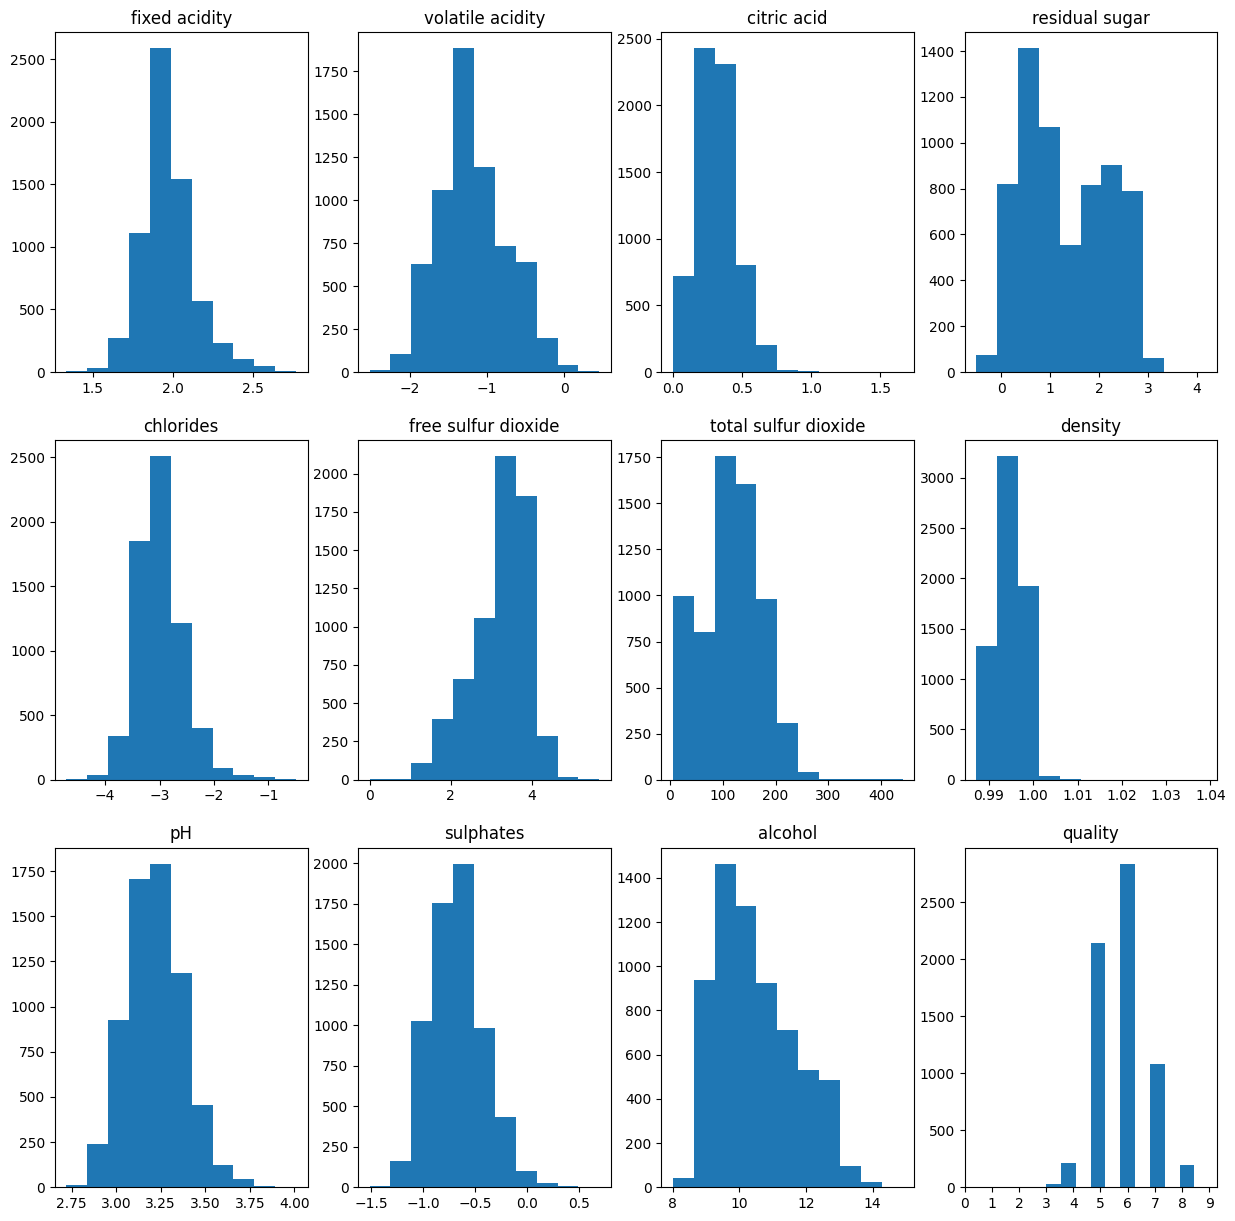

In [271]:
lines = 3
com = 4

fig, ax = plt.subplots(lines, com)
fig.set_figwidth(15)
fig.set_figheight(15)

for i in range(0, lines):
  for j in range(0, com):
    ax[i][j].hist(dados_tratados[i*com + j], bins=11)
    ax[i][j].set_title(wine_quality.columns[i*com + j])

ax[lines-1][com-1].set_xticks(range(0, 10))

plt.show()

In [272]:
total = dados_tratados

In [273]:
media_total = []
desvio_padrao_total = []


media_red = []
desvio_padrao_red = []

media_white = []
desvio_padrao_white = []



for i in range(0, preditores):
  media_total.append(total[i].mean())
  desvio_padrao_total.append(total[i].std())


  media_red.append(red[i].mean())
  desvio_padrao_red.append(red[i].std())

  media_white.append(white[i].mean())
  desvio_padrao_white.append(white[i].std())

## Normalização

In [274]:
total_norm = np.empty((preditores, total[0].size))


## Para os calculos
for i in range(0, preditores):
  for j in range(0, total[i].size):
    total_norm[i][j] = (total[i][j] - media_total[i])/desvio_padrao_total[i]

## Para plotar
red_norm = np.empty((preditores, red[0].size))
for i in range(0, preditores):
  for j in range(0, red[i].size):
    red_norm[i][j] = (red[i][j] - media_red[i])/desvio_padrao_red[i]

white_norm = np.empty((preditores, white[0].size))
for i in range(0, preditores):
  for j in range(0, white[i].size):
    white_norm[i][j] = (white[i][j] - media_white[i])/desvio_padrao_white[i]


In [275]:
heatmap = np.empty((preditores, preditores))
heatmap_red = np.empty((preditores, preditores))
heatmap_white = np.empty((preditores, preditores))

for i in range(0, preditores):
  for j in range(0, preditores):
    heatmap[i][j] = cov(total_norm[i], total_norm[j])
    heatmap_white[i][j] = cov(white_norm[i], white_norm[j])
    heatmap_red[i][j] = cov(red_norm[i], red_norm[j])


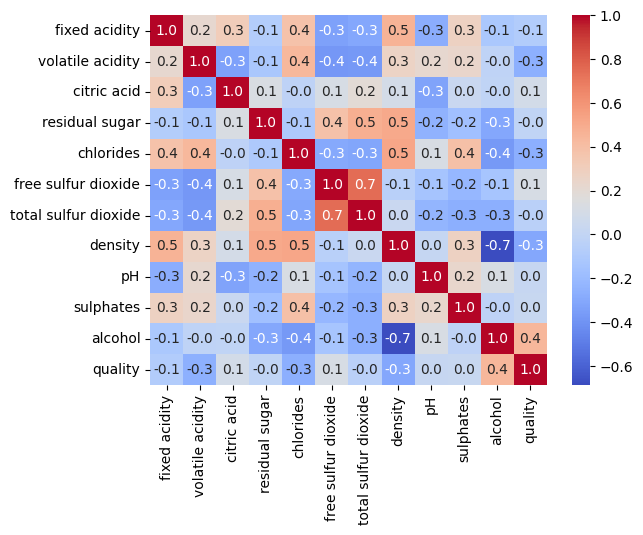

In [276]:
sns.heatmap(heatmap, annot=True, fmt='0.1f', cmap='coolwarm', xticklabels=wine_quality.columns, yticklabels=wine_quality.columns)
plt.show()

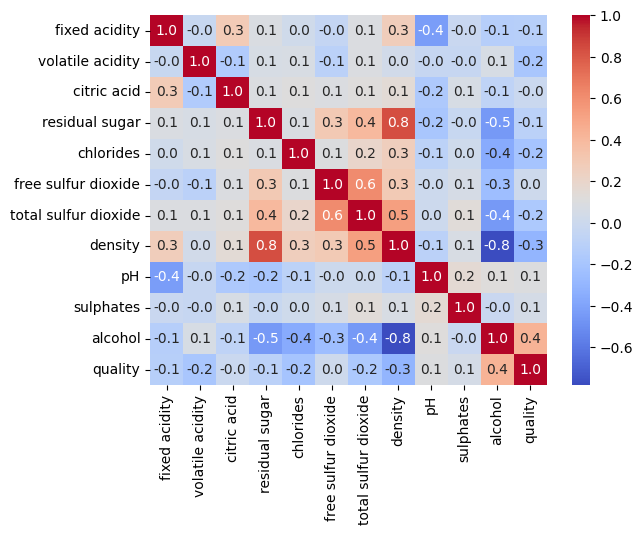

In [277]:
sns.heatmap(heatmap_white, annot=True, fmt='0.1f', cmap='coolwarm', xticklabels=wine_quality.columns, yticklabels=wine_quality.columns)
plt.show()

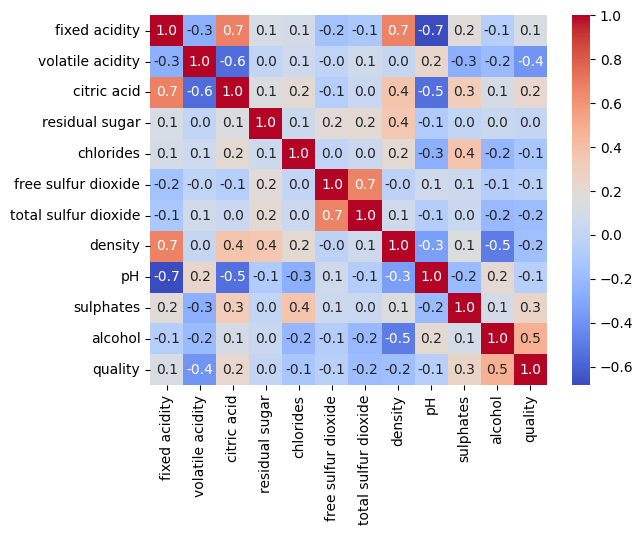

In [278]:
sns.heatmap(heatmap_red, annot=True, fmt='0.1f', cmap='coolwarm', xticklabels=wine_quality.columns, yticklabels=wine_quality.columns)
plt.show()

Pelo mapa de calor, podemos ver quais variáveis mais se correlacionam seja diretamente ou inversamente, para essa questão, pegaremos as que mais tem correlação entre si, sendo elas.


1.   Density x Alcohol | -0.7
2.   Free x Total sulfur dioxide | 0.7
3.   Density x Residual sugar | 0.6

In [279]:
'''
Remoção do Dioxido de enxofre total 6 - Muito correlato coom o livre
Remoção do Ácido volátil 1 - Muito correlato com o ácidio cítrico
Resto - Pouca correlação com a qualidade
'''
preditores_totais = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
preditores_list =  [1, 4, 7, 10, 11]  #[0, 1, 2, 3, 4, 5, 8, 9, 10, 11]

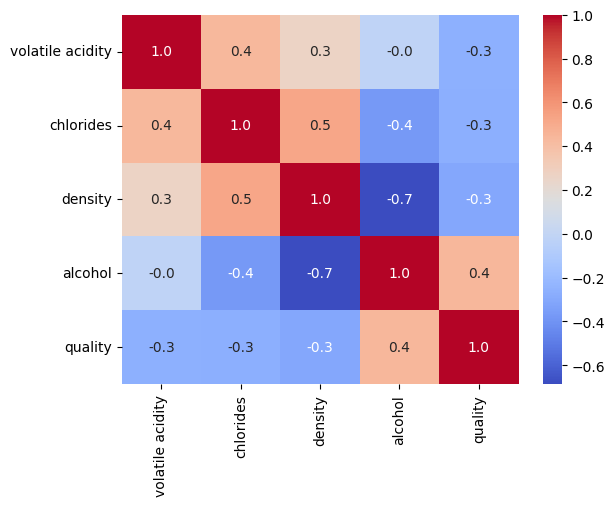

In [280]:
heatmap = np.empty((len(preditores_list), len(preditores_list)))

for i in range(0,len(preditores_list)):
  for j in range(0,len(preditores_list)):
    heatmap[i][j] = cov(total_norm[preditores_list[i]], total_norm[preditores_list[j]])

sns.heatmap(heatmap, annot=True, fmt='0.1f', cmap='coolwarm', xticklabels=wine_quality.columns[preditores_list], yticklabels=wine_quality.columns[preditores_list])
plt.show()

# Questão 1
Para esta etapa, faremos o a regressão linear, mas primeiramente tentaremos contrui-la.


Para o fazermos, utilizaremos o fato que todos os dados são independentes e uniformemente distribuidos, dessa forma, ao calcular:

$J(\beta) = \sum_{i=0}^{n}{(yi - ŷi)^2} = \sum_{i=0}^{n}{(yi - \beta_0 - \sum_{j=1}^{p}{\beta_jx_j})^2}$

Teremos que uma das maneiras que podemos chegar nos valores de β que alcancem o valor mínimo dessa soma de quadrados, utilizando matrizes, será:

$β = (X^TX)^{-1}X^TY$


## Gerando o modelo

In [281]:
preditores_usados = preditores_list

In [282]:
np.random.seed(2)

indices = np.random.permutation(tamanho)
total_data = total[preditores_usados].transpose().copy()[indices]


indice_treino = 4*tamanho//5

total_treino = total_data[0:indice_treino]
entradas = total_treino.transpose()[:len(preditores_usados) - 1]
saida = total_treino.transpose()[-1]


#Adicionando a coluna de 1's para o calculo de Y = BX
Xt = np.append([np.ones(entradas[0].size)], entradas, axis = 0)
X = Xt.transpose()

In [283]:
XtX = np.matmul(Xt,X)
A = np.matmul(inv(XtX), Xt) #(XtX)'Xt
B = np.matmul(A, saida)

## Análise de erros, etapa de teste

In [284]:
total_teste = total_data[indice_treino:]
entrada_teste = total_teste.transpose()[:len(preditores_usados) - 1]
saida_teste = total_teste.transpose()[-1]

entrada_teste = np.append([np.ones(entrada_teste[0].size)], entrada_teste, axis = 0).transpose()

In [285]:
tamanho_teste = saida_teste.size
saida_prevista = []

for i in range(0, tamanho_teste):
  reg = 0

  for j in range(0, len(preditores_usados)):
    reg = reg + entrada_teste[i][j] * B[j]

  saida_prevista.append(reg)

In [286]:
RMSE = np.sqrt(np.sum((saida_teste - saida_prevista)**2)/(tamanho_teste))
RMSEr = np.sqrt(np.sum((saida_teste - np.round(saida_prevista))**2)/(tamanho_teste ))

print(RMSE)
print(RMSEr)

0.7255791844802486
0.7765802747153208


In [287]:
RSS = np.sum((saida_teste - saida_prevista)**2)
TSS = np.sum((saida_teste - saida_teste.mean())**2)

R2 = 1 - RSS/TSS
print(R2)

0.2867606814516497


| Métrica | Sem Tratamento | Com tratamento |
| :--- | :---: | ---: |
| RMSE, todos os preditores | 0,719 |  0,70|
| RMSE, alguns preditores   | 0,736 | 0,733 |
| R², todos os preditores   | 0,30  |  0,32|
| R², alguns preditores     | 0,26  | 0,27 |


#QUESTÃO 1.2

Tendo em mente como fazer o nosso modelo, utilizaremos um método de croos validação para garantir que nosso

In [288]:
preditores_usados = preditores_list

total_data = total[preditores_usados].transpose().copy()[indices]

div = 5
n_c = tamanho//div

In [289]:
RMSE = []
R2 = []
Modelo_RMSE = []
Modelo_R2 = []

for i in range(0, div):
  indice_teste = i

  #Dados de teste
  total_teste = total_data[i*n_c:(i+1)*n_c]
  entrada_teste = total_teste.transpose()[:len(preditores_usados) - 1]
  entrada_teste = np.append([np.ones(entrada_teste[0].size)], entrada_teste, axis = 0).transpose()
  saida_teste = total_teste.transpose()[-1]

  #Dados de treino
  total_treino = np.append(total_data[: i*n_c], total_data[(i+1)*n_c:], axis=0)
  entradas = total_treino.transpose()[:len(preditores_usados) - 1]
  saida = total_treino.transpose()[-1]


  #Adicionando a coluna de 1's para o calculo de Y = BX
  Xt = np.append([np.ones(entradas[0].size)], entradas, axis = 0)
  X = Xt.transpose()

  #Gerando o modelo
  XtX = np.matmul(Xt,X)
  A = np.matmul(inv(XtX), Xt) #(XtX)'Xt
  B = np.matmul(A, saida)



  #Gerando modelo com biblioteca
  X_treino = total_treino.transpose()[:len(preditores_usados) - 1].transpose()
  Y_treino = saida
  modelo = LinearRegression()
  modelo.fit(X_treino, Y_treino)


  #Utilizando os dados de teste
  X_teste = total_teste.transpose()[:len(preditores_usados) - 1].transpose()

  #RMSE
  tamanho_teste = saida_teste.size
  saida_prevista = []

  for j in range(0, tamanho_teste):
    reg = 0

    for k in range(0, len(preditores_usados)):
      reg = reg + entrada_teste[j][k] * B[k]

    saida_prevista.append(reg)

  RMSE.append(np.sqrt(np.sum((saida_teste - saida_prevista)**2)/(tamanho_teste)))

  M_saida_prevista = modelo.predict(X_teste)
  Modelo_RMSE.append(np.sqrt(np.sum((saida_teste - M_saida_prevista)**2)/ (tamanho_teste)))

  #R^2
  RSS = np.sum((saida_teste - saida_prevista)**2)
  TSS = np.sum((saida_teste - saida_teste.mean())**2)

  mRSS = np.sum((saida_teste - M_saida_prevista)**2)
  mTSS = np.sum((saida_teste - saida_teste.mean())**2)

  R2.append(1 - RSS/TSS)
  Modelo_R2.append(1 - mRSS/mTSS)



In [290]:
RMSEm = np.mean(RMSE)
R2m = np.mean(R2)

MRMSEm = np.mean(Modelo_RMSE)
MR2m = np.mean(Modelo_R2)

print('Modelo Caseiro')
for i in range(0, div):
  print(f'it{i+1} RMSE: {RMSE[i]} || R2: {R2[i]}')

print('\nMedia:')
print(f'RMSE:{RMSEm: 0.2f}')
print(f'R²:{R2m: 0.2f}')

print('\nModelo da Biblioteca')
for i in range(0, div):
  print(f'it{i+1} RMSE: {Modelo_RMSE[i]} || R2: {Modelo_R2[i]}')

print('\nMedia:')
print(f'RMSE:{MRMSEm: 0.2f}')
print(f'R²:{MR2m: 0.2f}')


Modelo Caseiro
it1 RMSE: 0.7403641384850406 || R2: 0.270583786769798
it2 RMSE: 0.7396620933151584 || R2: 0.2612136276865239
it3 RMSE: 0.7720515915016732 || R2: 0.24333959056402377
it4 RMSE: 0.7534100393089083 || R2: 0.2818920350773374
it5 RMSE: 0.7259849313724055 || R2: 0.28586896812294826

Media:
RMSE: 0.75
R²: 0.27

Modelo da Biblioteca
it1 RMSE: 0.7403641384833041 || R2: 0.2705837867732195
it2 RMSE: 0.7396620933126531 || R2: 0.26121362769152867
it3 RMSE: 0.7720515915090654 || R2: 0.24333959054953413
it4 RMSE: 0.7534100393105807 || R2: 0.2818920350741493
it5 RMSE: 0.7259849313631337 || R2: 0.2858689681411891

Media:
RMSE: 0.75
R²: 0.27


| Métrica | Sem Tratamento | Com tratamento |
| :--- | :---: | ---: |
| RMSE, todos os preditores | 0,74 |  0,73 |
| RMSE, alguns preditores   | 0,75 | 0,75 |
| R², todos os preditores   | 0,29 |  0, 30|
| R², alguns preditores     | 0,26 | 0,27 |

Os resultados com a biblioteca foram iguais primeiras 2 casas decimais.

# Questão 2

Para essa questão, faremos o nosso modelo de Regressão, mas utilizando o penalizador de Ridge, pois é de mais fácil implementação, nele, queremos descobrir os valores dos coeficientes da seguinte maneira:

$J(\beta) = \sum{(yi - ŷi)^2} + λ\sum{β^2}$

E, ao transformar essa relação para a forma matricial, teremos que ela será da forma:

$β = (X^TX + λD)^{-1}X^TY$

Em que D é a matriz I, mas com a componente $(0,0) = 0$


Nesta questão, para descobrir o valor de λ, dividirei o conjuto de treino mais 5 subconjunto, de forma que para cada iteração, 4 deles serão para treino e 1 para validação.

In [329]:
preditores_usados = preditores_list
total_data = total[preditores_usados].transpose().copy()[indices]

In [330]:
n_t = 4*n_c//div

D = np.zeros((len(preditores_usados), len(preditores_usados)))


lambdas = np.arange(0, 100, 0.5)


for i in range(1, D.shape[0]):
  D[i][i] = 1

In [331]:
RMSE = []
RMSEr = []
R2 = []

MRMSE = []
MR2 = []

CV_RMSE = np.zeros(len(lambdas))
CV_R2 = np.zeros(len(lambdas))

for i in range(0, div):
  indice_teste = i

  #Dados de teste
  total_teste = total_data[i*n_c:(i+1)*n_c]
  entrada_teste = total_teste.transpose()[:len(preditores_usados) - 1]
  entrada_teste = np.append([np.ones(entrada_teste[0].size)], entrada_teste, axis = 0).transpose()
  saida_teste = total_teste.transpose()[-1]

  #Dados de treino
  total_treino = np.append(total_data[: i*n_c], total_data[(i+1)*n_c:], axis=0)
  entradas = total_treino.transpose()[:len(preditores_usados) - 1]
  saida = total_treino.transpose()[-1]

  vRSE = []
  vR2 = []

  for j in range(0, div):
    total_validacao = total_treino[j*n_t:(j+1)*n_t]
    entrada_validacao = total_validacao.transpose()[:len(preditores_usados) - 1]
    entrada_validacao = np.append([np.ones(entrada_validacao[0].size)], entrada_validacao, axis = 0).transpose()
    saida_validacao = total_validacao.transpose()[-1]

    sub_treino = np.append(total_treino[: j*n_t], total_treino[(j+1)*n_t:], axis=0)
    entradas_sub_treino = sub_treino.transpose()[:len(preditores_usados) - 1]
    sub_saida = sub_treino.transpose()[-1]

    RSE = []
    R2_fold = []

    for L in lambdas:
      Xt = np.append([np.ones(entradas_sub_treino[0].size)], entradas_sub_treino, axis = 0)
      X = Xt.transpose()

      XtX = np.matmul(Xt, X)
      A = np.matmul(inv(XtX + L*D), Xt)
      B = np.matmul(A, sub_saida)

      soma = 0
      saida_prevista_validacao = []

      for k in range(0, saida_validacao.size):
        reg = 0

        for z in range(0, len(preditores_usados)):
          reg = reg + entrada_validacao[k][z] * B[z]

        saida_prevista_validacao.append(reg)
        soma = soma + (saida_validacao[k] - reg)**2

      RSE.append(soma)

      RSS = soma
      TSS = np.sum((saida_validacao - saida_validacao.mean())**2)
      R2_fold.append(1 - RSS/TSS)


    vRSE = np.append(vRSE, RSE)
    vR2 = np.append(vR2, R2_fold)

  vRSE = vRSE.reshape((div, len(RSE))).transpose()
  vR2 = vR2.reshape((div, len(R2_fold))).transpose()

  Vs =[]
  for v in vRSE:
    Vs.append(np.sum(v))

  CV_RMSE += np.sqrt(np.array(Vs) / total_treino.shape[0])
  CV_R2 += np.mean(vR2, axis=1)

  L = lambdas[np.argmin(Vs)]
  print(f"Lambda Utilizado: {lambdas[np.argmin(Vs)]}")


  #Modelo Ridge usando função
  ridge = Ridge(alpha = L)
  X_treino = total_treino.transpose()[:len(preditores_usados) - 1].transpose()
  X_teste = total_teste.transpose()[:len(preditores_usados) - 1].transpose()
  ridge.fit(X_treino, saida)


  #Adicionando a coluna de 1's para o calculo de Y = BX
  Xt = np.append([np.ones(entradas[0].size)], entradas, axis = 0)
  X = Xt.transpose()

  #Gerando o modelo
  XtX = np.matmul(Xt,X)
  A = np.matmul(inv(XtX + L*D) , Xt) #(XtX)'Xt
  B = np.matmul(A, saida)





  #Utilizando os dados de teste

  #RMSE
  tamanho_teste = saida_teste.size
  saida_prevista = []

  for j in range(0, tamanho_teste):
    reg = 0

    for k in range(0, len(preditores_usados)):
      reg = reg + entrada_teste[j][k] * B[k]

    saida_prevista.append(reg)

  RMSE.append(np.sqrt(np.sum((saida_teste - saida_prevista)**2)/(tamanho_teste)))
  RMSEr.append(np.sqrt(np.sum((saida_teste - np.round(saida_prevista))**2)/(tamanho_teste )))

  M_saida_prevista = ridge.predict(X_teste)
  MRMSE.append(np.sqrt(np.sum((saida_teste - M_saida_prevista)**2)/(tamanho_teste)))

  #R^2
  RSS = np.sum((saida_teste - saida_prevista)**2)
  TSS = np.sum((saida_teste - saida_teste.mean())**2)

  MRSS = np.sum((saida_teste - M_saida_prevista)**2)

  R2.append(1 - RSS/TSS)
  MR2.append(1 - MRSS/TSS)

Lambda Utilizado: 0.0
Lambda Utilizado: 0.0
Lambda Utilizado: 0.0
Lambda Utilizado: 0.0
Lambda Utilizado: 0.0


Gráfico das modificações geradas pelos λ's.

Como podemos ver pelo gráfico, a mudança de λ provoca uma mudança infima no RMSE e no R².

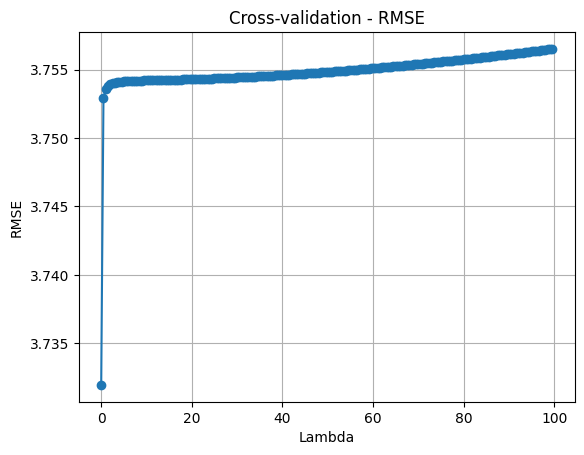

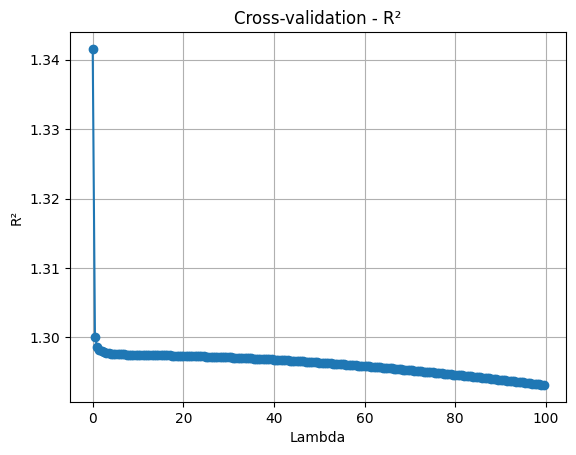

In [332]:
plt.plot(lambdas, CV_RMSE, marker='o')
plt.xlabel("Lambda")
plt.ylabel("RMSE")
plt.title("Cross-validation - RMSE")
plt.grid()
plt.show()

plt.plot(lambdas, CV_R2, marker='o')
plt.xlabel("Lambda")
plt.ylabel("R²")
plt.title("Cross-validation - R²")
plt.grid()
plt.show()

In [333]:
CV_RMSE /= div
CV_R2 /= div

for j in range(len(lambdas)):
  print(f"Lambda: {lambdas[j]:.2f} | RMSE: {CV_RMSE[j]:.4f} | R²: {CV_R2[j]:.4f}")

Lambda: 0.00 | RMSE: 0.7464 | R²: 0.2683
Lambda: 0.50 | RMSE: 0.7506 | R²: 0.2600
Lambda: 1.00 | RMSE: 0.7507 | R²: 0.2597
Lambda: 1.50 | RMSE: 0.7508 | R²: 0.2596
Lambda: 2.00 | RMSE: 0.7508 | R²: 0.2596
Lambda: 2.50 | RMSE: 0.7508 | R²: 0.2596
Lambda: 3.00 | RMSE: 0.7508 | R²: 0.2596
Lambda: 3.50 | RMSE: 0.7508 | R²: 0.2595
Lambda: 4.00 | RMSE: 0.7508 | R²: 0.2595
Lambda: 4.50 | RMSE: 0.7508 | R²: 0.2595
Lambda: 5.00 | RMSE: 0.7508 | R²: 0.2595
Lambda: 5.50 | RMSE: 0.7508 | R²: 0.2595
Lambda: 6.00 | RMSE: 0.7508 | R²: 0.2595
Lambda: 6.50 | RMSE: 0.7508 | R²: 0.2595
Lambda: 7.00 | RMSE: 0.7508 | R²: 0.2595
Lambda: 7.50 | RMSE: 0.7508 | R²: 0.2595
Lambda: 8.00 | RMSE: 0.7508 | R²: 0.2595
Lambda: 8.50 | RMSE: 0.7508 | R²: 0.2595
Lambda: 9.00 | RMSE: 0.7508 | R²: 0.2595
Lambda: 9.50 | RMSE: 0.7508 | R²: 0.2595
Lambda: 10.00 | RMSE: 0.7508 | R²: 0.2595
Lambda: 10.50 | RMSE: 0.7508 | R²: 0.2595
Lambda: 11.00 | RMSE: 0.7508 | R²: 0.2595
Lambda: 11.50 | RMSE: 0.7508 | R²: 0.2595
Lambda: 12.0

In [334]:
RMSEm = np.mean(RMSE)
R2m = np.mean(R2)

MRMSEm = np.mean(MRMSE)
MR2m = np.mean(MR2)

print('Modelo Caseiro')
for i in range(0, div):
  print(f'it{i+1} RMSE: {RMSE[i]} || R2: {R2[i]}')

print('\nMedia:')
print(f'RMSE:{RMSEm: 0.2f}')
print(f'R²:{R2m: 0.2f}')

print('\nModelo da Biblioteca')
for i in range(0, div):
  print(f'it{i+1} RMSE: {MRMSE[i]} || R2: {MR2[i]}')

print('\nMedia:')
print(f'RMSE:{MRMSEm: 0.2f}')
print(f'R²:{MR2m: 0.2f}')


Modelo Caseiro
it1 RMSE: 0.7403641384850406 || R2: 0.270583786769798
it2 RMSE: 0.7396620933151584 || R2: 0.2612136276865239
it3 RMSE: 0.7720515915016732 || R2: 0.24333959056402377
it4 RMSE: 0.7534100393089083 || R2: 0.2818920350773374
it5 RMSE: 0.7259849313724055 || R2: 0.28586896812294826

Media:
RMSE: 0.75
R²: 0.27

Modelo da Biblioteca
it1 RMSE: 0.7403641384833045 || R2: 0.2705837867732186
it2 RMSE: 0.7396620933126532 || R2: 0.26121362769152845
it3 RMSE: 0.7720515915090649 || R2: 0.24333959054953525
it4 RMSE: 0.7534100393105808 || R2: 0.28189203507414906
it5 RMSE: 0.7259849313631338 || R2: 0.2858689681411889

Media:
RMSE: 0.75
R²: 0.27


| Métrica | Sem Tratamento | Com tratamento |
| :--- | :---: | ---: |
| RMSE, todos os preditores | 0,74 | 0,73 |
| RMSE, alguns preditores   | 0,75 | 0,75 |
| R², todos os preditores   | 0,29 | 0,30 |
| R², alguns preditores     | 0,26 | 0,27 |


Os resultados com a biblioteca foram iguais nas primeiras 2 casas decimais.

# Questão 3

Nesta questão, antes de fazer nosos modelo, faremos a PCR de nossos dados (dados no banco de teste) e, posteriomente, aplicaremos nosso modelo para a aprendizagem com os preditores modificados.

## Gerando uma PCR

Nesta etapa, demostraremos oq será feito em cada etapa de cross validação, sendo:



1.   Normalizar/Padronizar os dados
2.   Gerar a matriz de covariancia
3.   Escolher um(uns) preditor(es)
4.   Projetar os dados nos novos preditores
5.   Gerar o modelo utilizando esses dados



In [297]:
preditores_PCR = 11 #Remoção da qualidade

heatmap = np.empty((preditores_PCR, preditores_PCR))

for i in range(0, preditores_PCR):
  for j in range(0, preditores_PCR):
    heatmap[i][j] = cov(total_norm[i], total_norm[j])


#Descobrindo os auto valores e auto vetores
lamb, v = np.linalg.eigh(heatmap)


In [298]:
sum = 0

for i in lamb:
  sum += i

lamb_percent = []

for i in lamb:
  lamb_percent.append(i/sum)

for i in range(0, len(lamb_percent)):
  print(f"{i} - {lamb_percent[i] * 100:.1f}%")

0 - 0.5%
1 - 1.9%
2 - 3.2%
3 - 3.7%
4 - 4.7%
5 - 5.6%
6 - 6.4%
7 - 8.7%
8 - 13.9%
9 - 23.0%
10 - 28.2%


In [299]:
preditores_usados = preditores_totais

In [300]:
total_data = total.transpose().copy()[indices]

In [301]:
total_PCR = []

for t in total_data:
  d = []

  for i in range(0, len(preditores_usados) -1):
    sum = 0

    for j in range(0, len(v[preditores_usados[i]])):
      sum = sum + t[j]*v[j][preditores_usados[i]]

    d.append(sum)

  d.append(t[-1])
  total_PCR.append(d)


In [302]:
total_data_PCR = np.asarray(total_PCR).transpose()

total_PCR_media = []
total_PCR_DP = []

for i in range(0, len(preditores_usados)):
  total_PCR_media.append(total_data_PCR[i].mean())
  total_PCR_DP.append(total_data_PCR[i].std())

total_PCR_norm = np.empty(total_data_PCR.shape)



## Para os calculos
for i in range(0, len(preditores_usados)):
  for j in range(0, total_data_PCR[i].size):
    total_PCR_norm[i][j] = (total_data_PCR[i][j] - total_PCR_media[i])/total_PCR_DP[i]


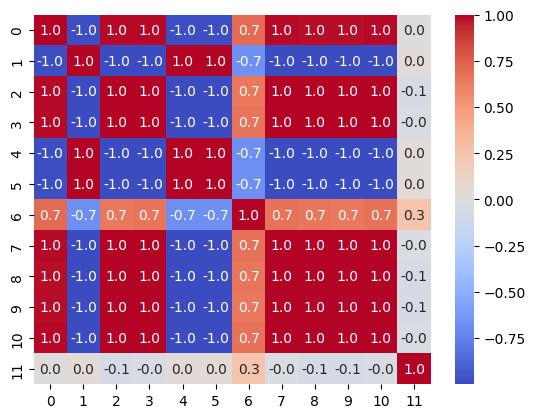

In [303]:
heatmap = np.empty((len(preditores_usados), len(preditores_usados)))

for i in range(0,heatmap.shape[0]):
  for j in range(0,heatmap.shape[1]):
    heatmap[i][j] = cov(total_PCR_norm[i], total_PCR_norm[j])

sns.heatmap(heatmap, annot=True, fmt='0.1f', cmap='coolwarm')
plt.show()

## Usando a PCR

Nesta etapa, faremos um modelo de regressão linear, mas utilizando preditores após a PCR. Para escolher os preditores, utilizamos a cross validação para ter certeza se a adição daquele preditor faz uma grande diferença ou não, pararemos de adiconar ao modelo final ao ver que os preditores não aumentam a eficiencia de modo significativo

In [308]:
total_data = total.transpose().copy()[indices]

In [309]:
RMSEm = []
R2m = []

for n_preditores in range(1, 12):

    RMSE = []
    R2 = []

    for i in range(0, div):

        # Separando treino e teste
        total_teste = total_data[i*n_c:(i+1)*n_c]

        total_treino = np.concatenate((total_data[:i*n_c],total_data[(i+1)*n_c:]), axis=0)

        # Separando entradas e saídas
        X_treino = total_treino[:, :-1]
        Y_treino = total_treino[:, -1]

        X_teste = total_teste[:, :-1]
        Y_teste = total_teste[:, -1]

        # Normalização usando apenas o treino
        media = X_treino.mean(axis=0)
        DP = X_treino.std(axis=0)

        X_treino_norm = (X_treino - media) / DP
        X_teste_norm = (X_teste - media) / DP

        # PCA
        heatmap = np.cov(X_treino_norm, rowvar=False)

        lamb, v = np.linalg.eigh(heatmap)

        # Ordenando os autovalores e autovetores
        ordem = np.argsort(lamb)[::-1]

        lamb = lamb[ordem]
        v = v[:, ordem]

        # Projetando os dados
        treino_PCR = X_treino_norm @ v
        teste_PCR = X_teste_norm @ v

        # Selecionando os primeiros componentes
        entradas = treino_PCR[:, :n_preditores]
        entrada_teste = teste_PCR[:, :n_preditores]

        # Regressão
        X = np.column_stack((
            np.ones(entradas.shape[0]),
            entradas
        ))

        Xt = np.column_stack((
            np.ones(entrada_teste.shape[0]),
            entrada_teste
        ))

        B = np.linalg.lstsq(X, Y_treino, rcond=None)[0]

        # Previsões
        saida_prevista = Xt @ B

        # RMSE
        RMSE.append(np.sqrt(np.mean(
            (Y_teste - saida_prevista)**2
        )))

        # R²
        RSS = np.sum((Y_teste - saida_prevista)**2)
        TSS = np.sum((Y_teste - Y_teste.mean())**2)

        R2.append(1 - RSS/TSS)

    RMSEm.append(np.mean(RMSE))
    R2m.append(np.mean(R2))

    print(f"Componentes: {n_preditores}")
    print(f"RMSEm: {RMSEm[-1]:.4f}")
    print(f"R²m: {R2m[-1]:.4f}")
    print("-" * 30)

Componentes: 1
RMSEm: 0.8571
R²m: 0.0353
------------------------------
Componentes: 2
RMSEm: 0.8213
R²m: 0.1143
------------------------------
Componentes: 3
RMSEm: 0.8066
R²m: 0.1457
------------------------------
Componentes: 4
RMSEm: 0.7896
R²m: 0.1812
------------------------------
Componentes: 5
RMSEm: 0.7637
R²m: 0.2340
------------------------------
Componentes: 6
RMSEm: 0.7616
R²m: 0.2383
------------------------------
Componentes: 7
RMSEm: 0.7586
R²m: 0.2443
------------------------------
Componentes: 8
RMSEm: 0.7587
R²m: 0.2441
------------------------------
Componentes: 9
RMSEm: 0.7295
R²m: 0.3012
------------------------------
Componentes: 10
RMSEm: 0.7280
R²m: 0.3040
------------------------------
Componentes: 11
RMSEm: 0.7282
R²m: 0.3036
------------------------------


In [310]:
# Encontrando a melhor quantidade de componentes
melhor_indice = np.argmin(RMSEm)
melhor_n = melhor_indice + 1

print("\n========== MELHOR MODELO ==========")

print(f"Preditores utilizados: {list(range(melhor_n))}")
print(f"Quantidade de componentes: {melhor_n}")
print(f"RMSEm final: {RMSEm[melhor_indice]:.4f}")
print(f"R²m final: {R2m[melhor_indice]:.4f}")


========== MELHOR MODELO ==========
Preditores utilizados: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Quantidade de componentes: 10
RMSEm final: 0.7280
R²m final: 0.3040


| Métrica | Sem Tratamento | Com tratamento |
| :--- | :---: | ---: |
| RMSE | 0,75 | 0,72 |
| R²   | 0,25 | 0,30 |

# Questão 4

Para está questão, utilizamos o modelo de regressão do sklearn, para sabermos se um modelo linear consegue ter uma taxa previssão melhor que os modelos utilizados anteriromente.

In [311]:
preditores_usados = preditores_list

In [312]:
total_data = total[preditores_usados].transpose().copy()[indices]

In [313]:
RMSE = []
R2 = []

for i in range(div):

    # Dados de treino
    total_treino = np.concatenate([
        total_data[:i*n_c],
        total_data[(i+1)*n_c:]
    ], axis=0)

    entradas = total_treino.transpose()[:len(preditores_usados)-1].copy()
    saida = total_treino.transpose()[-1].copy()

    M = entradas.mean(axis=1)
    DP = entradas.std(axis=1)

    DP[DP == 0] = 1

    entradas = ((entradas - M[:, None]) / DP[:, None]).transpose()

    # Dados de teste
    total_teste = total_data[i*n_c:(i+1)*n_c]

    entrada_teste = total_teste.transpose()[:len(preditores_usados)-1].copy()
    saida_teste = total_teste.transpose()[-1].copy()

    entrada_teste = (
        (entrada_teste - M[:, None]) / DP[:, None]
    ).transpose()

    # Rede neural
    regr = MLPRegressor(
        random_state=1,
        hidden_layer_sizes=(32, 32),
        max_iter=1000,
        tol=1e-4
    )

    regr.fit(entradas, saida)

    # Previsões
    saida_prevista = regr.predict(entrada_teste)

    # Métricas
    RMSE.append(np.sqrt(np.mean((saida_teste - saida_prevista)**2)))

    RMSEr.append(np.sqrt(
        np.mean((saida_teste - np.round(saida_prevista))**2)
    ))

    RSS = np.sum((saida_teste - saida_prevista)**2)
    TSS = np.sum((saida_teste - saida_teste.mean())**2)


    R2.append(1 - RSS/TSS)

In [314]:
RMSEm = np.mean(RMSE)
R2m = np.mean(R2)

for i in range(0, div):
  print(f'it{i+1} RMSE: {RMSE[i]} || R2: {R2[i]}')

print('\nMedia:')
print(f'RMSE:{RMSEm: 0.2f}')
print(f'R²:{R2m: 0.2f}')


it1 RMSE: 0.7296563986693675 || R2: 0.2915300171417704
it2 RMSE: 0.726330992801388 || R2: 0.28760427703787694
it3 RMSE: 0.7650965869456657 || R2: 0.25691089270936895
it4 RMSE: 0.7404846077095109 || R2: 0.306320262957434
it5 RMSE: 0.7156619313371324 || R2: 0.3060334706589176

Media:
RMSE: 0.74
R²: 0.29


| Métrica | Sem Tratamento | Com tratamento |
| :--- | :---: | ---: |
| RMSE, todos os preditores | 0,70 |  0,70 |
| RMSE, alguns preditores   | 0,74 | 0,74|
| R², todos os preditores   | 0,36 | 0,37 |
| R², alguns preditores     | 0,29 | 0,29|

A arquitetura do modelo com duas camadas internas, cada uma com dois neuronios foi utilizada, pois, ao utilizar o um modelo (64, 32, 32), não foi apresentando mudanças aparentes tanto no RMSE, quanto no R², portanto, adicionar mais uma cada não fará diferença, ao diminuir o tamanho de neurônios, com (32, 16), foi observado um aumento de RMSE e diminuição do R²